# Partie 1 : méthodes d'ensemble

Ce notebook présente la partie 1 de bout en bout, de haut en bas. Il **relit** les résultats déjà calculés dans `results/`

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "code"))
RES = ROOT / "results"
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


## load datasets

21 jeux réels du cours. Un jeu est dit **déséquilibré** si sa classe minoritaire représente moins de 20 % des exemples, dans ce cas, l'accuracy est trompeuse, car prédire toujours la classe majoritaire donne déjà plus de 80 %.


In [2]:
datasets = pd.read_csv(RES / "datasets.csv")
datasets = datasets[datasets.data != "bankmarketing"].sort_values("minority")
print(len(datasets), "jeux dont", int(datasets.imbalanced.sum()), "déséquilibrés")
datasets.reset_index(drop=True)

21 jeux dont 6 déséquilibrés


,data,m,d,minority,imbalanced
0,libras,360,90,0.067,True
1,satimage,6435,36,0.097,True
2,pageblocks,5473,10,0.102,True
3,yeast3,1484,8,0.110,True
4,abalone8,4177,10,0.136,True
5,segmentation,2310,19,0.143,True
6,vehicle,846,18,0.235,False
7,german,1000,24,0.300,False
8,newthyroid,215,5,0.302,False
9,glass,214,9,0.327,False


##  Démo de nos trois implémentations

On les essaie sur wdbc (diagnostic de cancer du sein, 569 exemples). 

In [3]:
import benchkit as bk
from ensemble_methods import Bagging, AdaBoost, Stacking
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

X, y = bk.real_dataset("wdbc")
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
err = lambda m: np.mean(m.predict(Xte) != yte)

tree = DecisionTreeClassifier(random_state=0).fit(Xtr, ytr)
bag = Bagging(100, random_state=0).fit(Xtr, ytr)
ada1 = AdaBoost(200, 1).fit(Xtr, ytr)
ada3 = AdaBoost(200, 3).fit(Xtr, ytr)
stack = Stacking(random_state=0).fit(Xtr, ytr)

pd.Series({"arbre seul": err(tree), "bagging": err(bag), "AdaBoost (stumps)": err(ada1),
           "AdaBoost (profondeur 3)": err(ada3), "stacking": err(stack)}, name="erreur de test").round(3).to_frame()

,erreur de test
arbre seul,0.094
bagging,0.064
AdaBoost (stumps),0.053
AdaBoost (profondeur 3),0.047
stacking,0.058


**Erreur out-of-bag (OOB).** Pour chaque exemple d'entraînement, on fait voter seulement les arbres du bagging qui ne l'ont pas vu. Cette erreur est calculée sans toucher au jeu de test, mais doit en être proche.

In [4]:
print("part des exemples jamais tirés dans un bootstrap : ~", round((1 - 1 / len(ytr)) ** len(ytr), 3))
print("erreur OOB  :", round(bag.oob_error_, 3))
print("erreur test :", round(err(bag), 3))

part des exemples jamais tirés dans un bootstrap : ~ 0.367
erreur OOB  : 0.048
erreur test : 0.064


**Borne du cours sur AdaBoost.** L'erreur d'entraînement est majorée par le produit des constantes de normalisation $Z_t$. On le vérifie, et on regarde l'erreur après 1, 2, ... tours.

après 5 tours : erreur d'entraînement = 0.0226 <= produit des Z_t = 0.1389


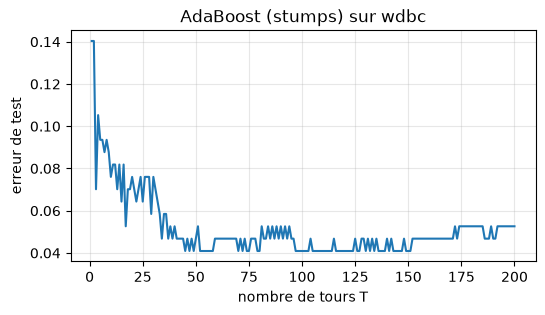

In [5]:
ada5 = AdaBoost(5, 1).fit(Xtr, ytr)
train_err = np.mean(ada5.predict(Xtr) != ytr)
print("après 5 tours : erreur d'entraînement =", round(train_err, 4), "<= produit des Z_t =", round(float(np.prod(ada5.Z_)), 4))

staged = [np.mean(np.where(S >= 0, 1, -1) != yte) for S in ada1.staged_decision_function(Xte)]
plt.figure(figsize=(6, 3)); plt.plot(range(1, len(staged) + 1), staged)
plt.xlabel("nombre de tours T"); plt.ylabel("erreur de test"); plt.title("AdaBoost (stumps) sur wdbc"); plt.show()

##  Validation contre scikit-learn

In [6]:
val = pd.read_csv(RES / "validation.csv")
val["écart bagging"] = (val.bag_ours - val.bag_sk).round(4)
val["écart AdaBoost"] = (val.ada_ours - val.ada_sk).round(4)
val["écart stacking"] = (val.stack_ours - val.stack_sk).round(4)
val

,data,bag_ours,bag_sk,bag_oob,ada_ours,ada_sk,stack_ours,stack_sk,écart bagging,écart AdaBoost,écart stacking
0,wdbc,0.0433,0.0480,0.0452,0.0386,0.0386,0.0292,0.0316,-0.0047,0.0,-0.0024
1,pima,0.2268,0.2329,0.2521,0.2208,0.2208,0.2208,0.2208,-0.0061,0.0,0.0000
2,australian,0.1382,0.1382,0.1408,0.1585,0.1585,0.1372,0.1362,0.0000,0.0,0.0010
3,spambase,0.0609,0.0620,0.0565,0.0610,0.0610,0.0622,0.0619,-0.0011,0.0,0.0003
4,satimage,0.0607,0.0589,0.0593,0.0765,0.0765,0.0585,0.0588,0.0018,0.0,-0.0003



10 méthodes, 21 jeux, 10 découpages. Pour chaque jeu, on classe les méthodes (rang 1 = meilleure) et on moyenne les rangs. 

Friedman sur l'erreur : p = 7.6e-11 ; distance critique CD = 2.96 ; N = 21 jeux


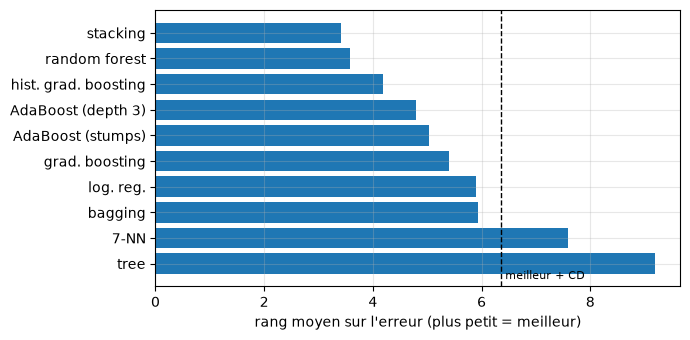

In [7]:
ranks = pd.read_csv(RES / "ranks_summary.csv")
r = ranks[(ranks.metric == "err") & (ranks.group == "all")].iloc[0]
methods = list(ranks.columns[6:])
print(f"Friedman sur l'erreur : p = {r.p:.1e} ; distance critique CD = {r.CD:.2f} ; N = {int(r.N)} jeux")

s = r[methods].astype(float).sort_values()
plt.figure(figsize=(7, 3.5))
plt.barh(s.index[::-1], s.values[::-1])
plt.xlabel("rang moyen sur l'erreur (plus petit = meilleur)")
plt.axvline(s.min() + r.CD, ls="--", c="k", lw=1)
plt.text(s.min() + r.CD, -0.6, " meilleur + CD", fontsize=8)
plt.tight_layout(); plt.show()

Rangs moyens selon la métrique et le groupe de jeux :

In [8]:
ranks[ranks.group == "all"].set_index("metric")[methods].round(1)

,tree,log. reg.,7-NN,bagging,AdaBoost (stumps),AdaBoost (depth 3),stacking,random forest,grad. boosting,hist. grad. boosting
metric,,,,,,,,,,
err,9.2,5.9,7.6,5.9,5.0,4.8,3.4,3.6,5.4,4.2
bacc,8.3,6.5,7.6,5.4,5.1,4.5,4.2,4.3,5.1,3.9
f1min,8.5,6.6,7.4,5.7,5.1,4.6,4.1,4.2,5.1,3.8
auc,9.9,5.8,7.7,6.2,5.2,4.6,3.2,3.3,5.2,3.8


**Comparaisons par paires** (test de Wilcoxon avec correction de Holm, sur l'erreur) : 
wins_a`= nombre de jeux où la méthode 
`a` est meilleure que `b`, sur 21.

In [9]:
pw = pd.read_csv(RES / "pairwise_err.csv")
pw.round(4).head(15)

,a,b,mean_diff,wins_a,losses_a,p,p_holm
0,bagging,tree,-0.0422,21,0,0.0000,0.0000
1,AdaBoost (depth 3),tree,-0.0481,21,0,0.0000,0.0000
2,random forest,tree,-0.0529,21,0,0.0000,0.0000
3,grad. boosting,tree,-0.0457,21,0,0.0000,0.0000
4,hist. grad. boosting,tree,-0.0494,21,0,0.0000,0.0000
5,stacking,tree,-0.0532,20,1,0.0000,0.0000
6,random forest,bagging,-0.0107,20,1,0.0000,0.0000
7,AdaBoost (stumps),tree,-0.0497,19,2,0.0000,0.0000
8,stacking,log. reg.,-0.0246,18,2,0.0010,0.0092
9,random forest,log. reg.,-0.0243,12,9,0.0701,0.5611


## on voit si le Bagging ou boosting est mieux 

Pour chaque jeu, `bag_minus_ada1` = erreur du bagging moins erreur d'AdaBoost (stumps) : **positif = le boosting gagne**. On regarde si le signe dépend de la taille, de la dimension ou du déséquilibre.

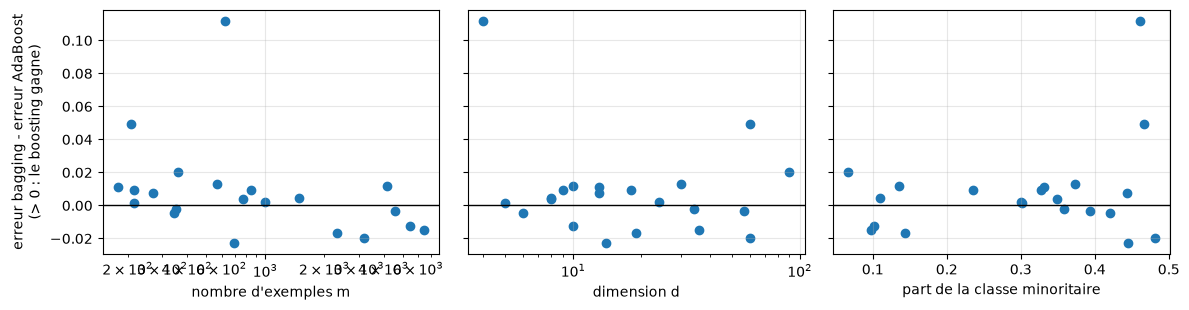

AdaBoost (stumps) meilleur que le bagging sur 13 jeux sur 21


,data,m,d,minority,bag,ada1,ada3,rf,gb,bag_minus_ada1,bag_minus_ada3
1,australian,690,14,0.445,0.129,0.151,0.151,0.124,0.134,-0.023,-0.022
16,splice,3175,60,0.481,0.039,0.059,0.032,0.029,0.031,-0.020,0.007
13,segmentation,2310,19,0.143,0.026,0.042,0.012,0.019,0.021,-0.017,0.014
12,satimage,6435,36,0.097,0.061,0.076,0.058,0.059,0.064,-0.015,0.002
10,pageblocks,5473,10,0.102,0.026,0.038,0.026,0.025,0.027,-0.012,-0.000
3,bupa,345,6,0.420,0.271,0.276,0.306,0.263,0.280,-0.005,-0.035
15,spambase,4597,57,0.394,0.058,0.061,0.052,0.049,0.055,-0.003,0.006
7,iono,351,34,0.359,0.084,0.086,0.074,0.066,0.074,-0.002,0.010
9,newthyroid,215,5,0.302,0.049,0.048,0.052,0.042,0.049,0.002,-0.003
4,german,1000,24,0.300,0.244,0.242,0.258,0.240,0.240,0.002,-0.014


In [10]:
bb = pd.read_csv(RES / "bag_vs_boost.csv").sort_values("bag_minus_ada1")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, col, lab in zip(ax, ["m", "d", "minority"], ["nombre d'exemples m", "dimension d", "part de la classe minoritaire"]):
    a.scatter(bb[col], bb.bag_minus_ada1); a.axhline(0, c="k", lw=1)
    a.set_xlabel(lab)
    if col in ("m", "d"): a.set_xscale("log")
ax[0].set_ylabel("erreur bagging - erreur AdaBoost\n(> 0 : le boosting gagne)")
plt.tight_layout(); plt.show()
print("AdaBoost (stumps) meilleur que le bagging sur", int((bb.bag_minus_ada1 > 0).sum()), "jeux sur", len(bb))
bb.round(3)

## noise des labels


In [11]:
A = pd.read_csv(RES / "exp_A_sim_noise.csv")
tab = A.groupby(["problem", "noise", "model"]).err.mean().unstack("model")
tab[["tree", "bagging", "adaboost_stumps", "adaboost_depth3", "rf", "gb"]].round(3)

model                tree  bagging  adaboost_stumps  adaboost_depth3     rf     gb
problem      noise                                                                
additive     0.0    0.128    0.094            0.060            0.075  0.086  0.081
             0.1    0.213    0.111            0.141            0.151  0.099  0.117
             0.2    0.280    0.153            0.183            0.219  0.142  0.170
checkerboard 0.0    0.229    0.112            0.507            0.078  0.196  0.286
             0.1    0.416    0.236            0.502            0.298  0.284  0.367
             0.2    0.401    0.336            0.507            0.358  0.351  0.405
ringnorm     0.0    0.207    0.082            0.056            0.056  0.057  0.064
             0.1    0.260    0.087            0.100            0.111  0.060  0.088
             0.2    0.306    0.105            0.133            0.169  0.075  0.121
threenorm    0.0    0.320    0.177            0.191            0.168  0.155  0.173
             0.1    0.339    0.190            0.223            0.212  0.172  0.206
             0.2    0.379    0.219            0.267            0.272  0.198  0.240
twonorm      0.0    0.201    0.048            0.042            0.036  0.035  0.047
             0.1    0.245    0.059            0.107            0.088  0.044  0.079
             0.2    0.285    0.078            0.152            0.155  0.054  0.110

**Jeux réels** (bloc F) : erreur moyenne selon le bruit.

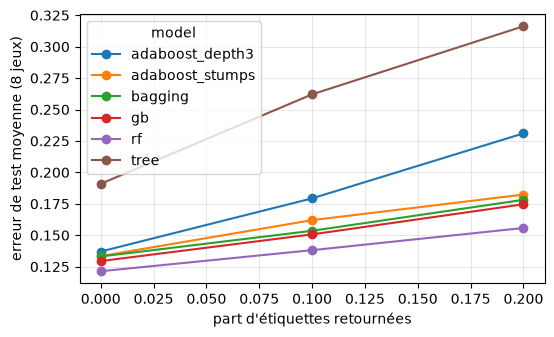

In [12]:
F = pd.read_csv(RES / "exp_F_realnoise.csv")
m = F.groupby(["noise", "model"]).err.mean().unstack("model")
ax = m.plot(marker="o", figsize=(6, 3.5)); ax.set_ylabel("erreur de test moyenne (8 jeux)")
ax.set_xlabel("part d'étiquettes retournées")
plt.show()

**Erreur selon le nombre de tours** (bloc B) : l'erreur d'entraînement d'AdaBoost tend vers 0 ; l'erreur de test, elle, peut remonter si les données sont bruitées.

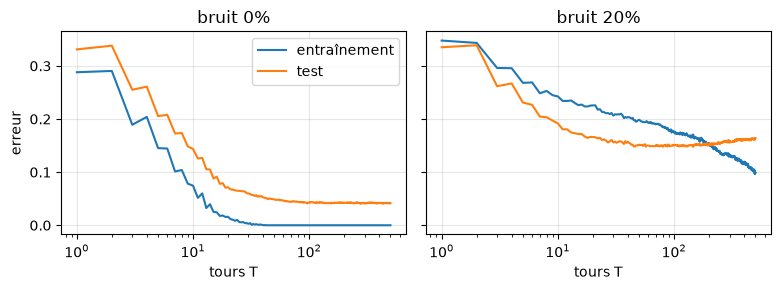

In [13]:
B = pd.read_csv(RES / "exp_B_rounds.csv")
fig, ax = plt.subplots(1, B.noise.nunique(), figsize=(4 * B.noise.nunique(), 3), sharey=True)
for a, (eta, g) in zip(np.atleast_1d(ax), B[B.model == "adaboost_stumps"].groupby("noise")):
    g = g.groupby("T")[["train_err", "test_err"]].mean()
    a.plot(g.index, g.train_err, label="entraînement"); a.plot(g.index, g.test_err, label="test")
    a.set_xscale("log"); a.set_title(f"bruit {eta:.0%}"); a.set_xlabel("tours T")
np.atleast_1d(ax)[0].legend(); np.atleast_1d(ax)[0].set_ylabel("erreur")
plt.tight_layout(); plt.show()

**Profondeur des arbres** (bloc C) : des arbres profonds conviennent au bagging, des arbres très simples au boosting.

In [14]:
C = pd.read_csv(RES / "exp_C_depth.csv")
C["depth"] = C.depth.replace(0, np.nan)
C.groupby(["method", "depth"], dropna=False).err.mean().unstack("method").round(3)

method,adaboost,bagging,single tree
depth,,,
1.0,0.109,0.217,0.224
2.0,0.108,0.169,0.183
3.0,0.108,0.140,0.156
5.0,0.110,0.122,0.150
8.0,0.123,0.114,0.150
NaN,NaN,0.112,0.159


## classes déséquilibrées

Sur les 6 jeux déséquilibrés, la précision flatte tout le monde. On compare l'erreur et la **balanced accuracy** (moyenne du rappel de chaque classe) : le classement des méthodes dépend de la métrique.

In [15]:
bench = pd.read_csv(RES / "benchmark.csv")
dsets = pd.read_csv(RES / "datasets.csv").set_index("data")
bench["imb"] = bench.data.map(dsets.imbalanced)
sub = bench[bench.imb == True]
print(sub.data.nunique(), "jeux déséquilibrés :", ", ".join(sorted(sub.data.unique())))
g = sub.groupby("model")[["err", "bacc", "f1min", "auc"]].mean().round(3)
g["acc"] = (1 - g.err).round(3)
g[["acc", "bacc", "f1min", "auc"]].sort_values("bacc", ascending=False)

6 jeux déséquilibrés : abalone8, libras, pageblocks, satimage, segmentation, yeast3


,acc,bacc,f1min,auc
model,,,,
hgb,0.947,0.821,0.708,0.943
stacking,0.947,0.814,0.687,0.945
adaboost_depth3,0.947,0.813,0.681,0.942
gb,0.944,0.794,0.648,0.937
adaboost_stumps,0.940,0.793,0.634,0.932
bagging,0.941,0.785,0.641,0.932
tree,0.916,0.784,0.616,0.784
rf,0.944,0.781,0.643,0.944
7nn,0.938,0.779,0.640,0.919


## stacking

On le compare à son meilleur membre (arbre, régression logistique, 7-NN, Naive Bayes, SVM), à un vote uniforme, et à un stacking naïf (sans out-of-fold) qui montre le piège. Le coût est mesuré par le temps d'entraînement.

In [16]:
E = pd.read_csv(RES / "exp_E_stacking.csv")
cols = ["stacking", "stacking_naive", "uniform_vote", "best_member_cv", "best_member_oracle", "mean_member"]
print("erreur moyenne sur", E.data.nunique(), "jeux :")
print(E[cols].mean().round(4).to_string())
print("\ntemps du stacking / temps des modèles de base seuls, médiane :", round((E.t_stacking / E.t_members).median(), 1))

erreur moyenne sur 21 jeux :
stacking              0.0999
stacking_naive        0.1225
uniform_vote          0.1083
best_member_cv        0.1038
best_member_oracle    0.0972
mean_member           0.1480

temps du stacking / temps des modèles de base seuls, médiane : 7.1


## Réponses aux quatre questions du sujet

| Question | Ce que montrent les résultats |
| --- | --- |
| Gain d'un ensemble sur un arbre seul et sur un autre type de modèle | très net contre l'arbre ; contre la régression logistique, le gain est faible sauf pour le stacking. |
| Bagging ou boosting | pas de gagnant global ; le bagging résiste mieux au bruit, le boosting profite des données propres. |
| Stacking contre son meilleur membre |  légèrement meilleur que le meilleur membre choisi par validation, mais pas significativement ; coût d'environ 7 fois plus de temps. |
| Données déséquilibrées |la précision est trompeuse ; le classement change selon la métrique. |

